# Week 6  
For Week 6, include concepts such as decision trees and random forests. Complete your Jupyter Notebook homework by 11:59pm ET on Sunday. 

**Import Libraries**

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_absolute_error

import optuna
from optuna.visualization import (
    plot_optimization_history, 
    plot_param_importances, 
    plot_parallel_coordinate
)
from sklearn.ensemble import RandomForestClassifier

**Load Data**

In [2]:
diabetes_indicators = pd.read_csv('Modified_Datasets/diabetes_indicators_2.csv')

In [3]:
cervical_cancer = pd.read_csv('Modified_Datasets/cervical_cancer_2.csv')

**Random Forest** (includes decision trees)

*Diabetes*

In [4]:
kf = KFold(n_splits = 3,
           shuffle = True,
           random_state = 42)

In [5]:
# X, y
Xd = diabetes_indicators.drop('Diabetes_012', axis = 1)
yd = diabetes_indicators['Diabetes_012']
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size = 0.2, random_state = 42)

In [6]:
# Create an objective function
def dobjective_function(trial): 
    params = {
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy', 'log_loss']),
        'max_depth': trial.suggest_categorical('max_depth', [None] + list(range(1, 41))),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),  
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 2, 20),  
        'max_leaf_nodes': trial.suggest_int('max_leaf_nodes', 2, 1000),  
        'max_features': trial.suggest_categorical('max_features', [None, 'sqrt', 'log2']), 
        'ccp_alpha': trial.suggest_float('ccp_alpha', 1e-5, 0.5, log = True)  
}

    rf = RandomForestClassifier(**params)

    cv_scores_rf = cross_val_score(
        rf, 
        Xd_train, 
        yd_train, 
        cv = kf, 
        scoring = 'recall_weighted'
    )

    return cv_scores_rf.mean()

In [7]:
# Set up Optuna study
dstudy = optuna.create_study(direction = 'maximize')

dstudy.optimize(dobjective_function, n_trials = 100)

[I 2026-10-15 23:50:09,137] A new study created in memory with name: no-name-af8847eb-f30b-4471-b82a-b5c679ea65a2
[I 2026-10-15 23:52:02,172] Trial 0 finished with value: 0.8336561077541083 and parameters: {'criterion': 'gini', 'max_depth': 32, 'min_samples_split': 3, 'min_samples_leaf': 12, 'max_leaf_nodes': 807, 'max_features': None, 'ccp_alpha': 5.9377667065493274e-05}. Best is trial 0 with value: 0.8336561077541083.
[I 2026-10-15 23:52:40,456] Trial 1 finished with value: 0.8265460481453727 and parameters: {'criterion': 'entropy', 'max_depth': 34, 'min_samples_split': 16, 'min_samples_leaf': 4, 'max_leaf_nodes': 957, 'max_features': 'sqrt', 'ccp_alpha': 0.17779304992307754}. Best is trial 0 with value: 0.8336561077541083.
[I 2026-10-15 23:52:59,608] Trial 2 finished with value: 0.8265460481453727 and parameters: {'criterion': 'gini', 'max_depth': 6, 'min_samples_split': 16, 'min_samples_leaf': 10, 'max_leaf_nodes': 818, 'max_features': 'log2', 'ccp_alpha': 0.0012967329489937333}. B

In [8]:
# Display results
dresults = dstudy.trials_dataframe()

dresults = dresults.sort_values(by = 'value', ascending = False)

display(dresults.head(5))

,number,value,datetime_start,datetime_complete,duration,params_ccp_alpha,params_criterion,params_max_depth,params_max_features,params_max_leaf_nodes,params_min_samples_leaf,params_min_samples_split,system_attrs_tpe:relative_params:0,state
70,70,0.834619,2026-10-16 01:32:51.845457,2026-10-16 01:33:50.336651,0 days 00:00:58.491194,0.000024,gini,23.0,log2,985,2,19,"{""ccp_alpha"": 2.3715888933792264e-05, ""criteri...",COMPLETE
55,55,0.834570,2026-10-16 01:18:43.325915,2026-10-16 01:19:49.374949,0 days 00:01:06.049034,0.000010,gini,28.0,log2,907,2,20,"{""ccp_alpha"": 1.042890070249497e-05, ""criterio...",COMPLETE
98,98,0.834559,2026-10-16 01:53:35.918744,2026-10-16 01:54:04.020583,0 days 00:00:28.101839,0.000010,gini,29.0,log2,986,2,18,"{""ccp_alpha"": 1.0097637627385316e-05, ""criteri...",COMPLETE
61,61,0.834521,2026-10-16 01:24:06.545769,2026-10-16 01:25:06.463537,0 days 00:00:59.917768,0.000011,gini,23.0,log2,925,2,19,"{""ccp_alpha"": 1.1100588683573644e-05, ""criteri...",COMPLETE
31,31,0.834510,2026-10-16 00:34:49.143603,2026-10-16 00:35:36.189641,0 days 00:00:47.046038,0.000017,gini,27.0,log2,890,8,7,"{""ccp_alpha"": 1.660872933973542e-05, ""criterio...",COMPLETE


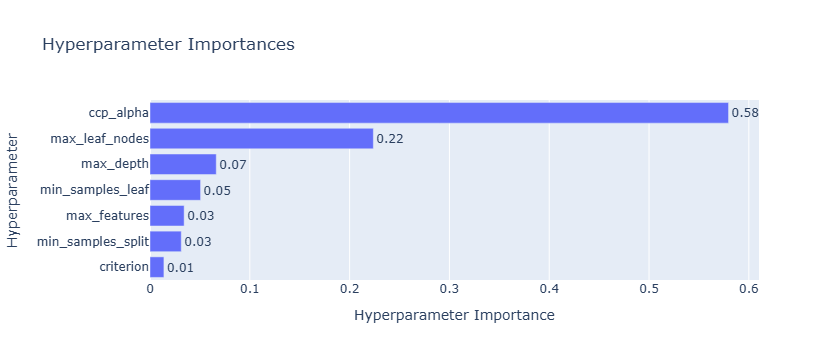

In [9]:
# Plot of which hyperparameters were the most important
plot_param_importances(dstudy).show()

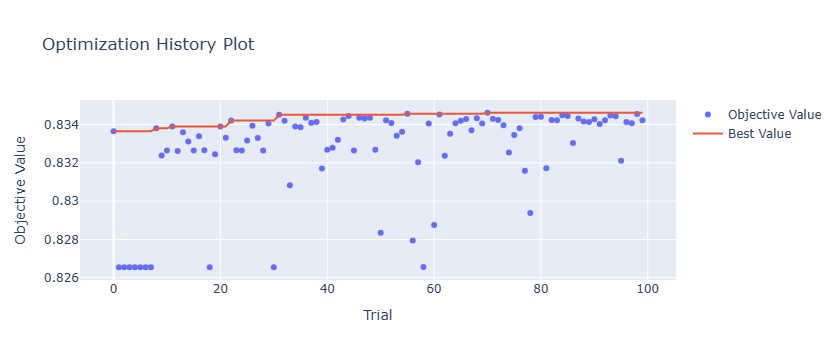

In [10]:
plot_optimization_history(dstudy).show()

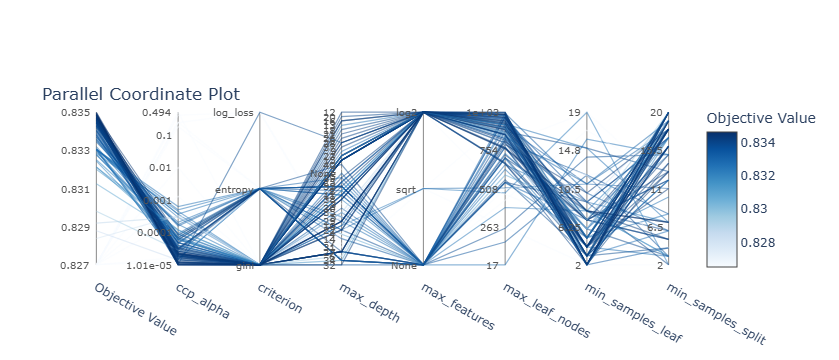

In [11]:
plot_parallel_coordinate(dstudy).show()

*Cervical Cancer*

In [12]:
# X, y
Xc = cervical_cancer.drop('Dx:Cancer', axis = 1)
yc = cervical_cancer['Dx:Cancer']
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size = 0.2, random_state = 42)

In [13]:
# Create an objective function
def cobjective_function(trial): 
    params = {
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy', 'log_loss']),
        'max_depth': trial.suggest_categorical('max_depth', [None] + list(range(1, 41))),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),  
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 2, 20),  
        'max_leaf_nodes': trial.suggest_int('max_leaf_nodes', 2, 1000),  
        'max_features': trial.suggest_categorical('max_features', [None, 'sqrt', 'log2']), 
        'ccp_alpha': trial.suggest_float('ccp_alpha', 1e-5, 0.5, log = True)  
}

    rf = RandomForestClassifier(**params)

    cv_scores_rf = cross_val_score(
        rf, 
        Xc_train, 
        yc_train, 
        cv = kf, 
        scoring = 'recall'
    )

    return cv_scores_rf.mean()

In [14]:
# Set up Optuna study
cstudy = optuna.create_study(direction = 'maximize')

cstudy.optimize(cobjective_function, n_trials = 100)

[I 2026-10-16 01:54:34,876] A new study created in memory with name: no-name-eb9246ee-e713-410e-a30a-3b8aa2ea6290
[I 2026-10-16 01:54:35,288] Trial 0 finished with value: 0.0 and parameters: {'criterion': 'entropy', 'max_depth': 35, 'min_samples_split': 6, 'min_samples_leaf': 11, 'max_leaf_nodes': 932, 'max_features': 'log2', 'ccp_alpha': 0.0003967759615855106}. Best is trial 0 with value: 0.0.
[I 2026-10-16 01:54:35,659] Trial 1 finished with value: 0.0 and parameters: {'criterion': 'gini', 'max_depth': 1, 'min_samples_split': 15, 'min_samples_leaf': 20, 'max_leaf_nodes': 854, 'max_features': 'log2', 'ccp_alpha': 0.010034928717679699}. Best is trial 0 with value: 0.0.
[I 2026-10-16 01:54:36,033] Trial 2 finished with value: 0.0 and parameters: {'criterion': 'entropy', 'max_depth': 16, 'min_samples_split': 5, 'min_samples_leaf': 10, 'max_leaf_nodes': 450, 'max_features': 'sqrt', 'ccp_alpha': 0.006301338412683273}. Best is trial 0 with value: 0.0.
[I 2026-10-16 01:54:36,342] Trial 3 fin

In [15]:
# Display results
cresults = cstudy.trials_dataframe()

cresults = cresults.sort_values(by = 'value', ascending = False)

display(cresults.head(5))

,number,value,datetime_start,datetime_complete,duration,params_ccp_alpha,params_criterion,params_max_depth,params_max_features,params_max_leaf_nodes,params_min_samples_leaf,params_min_samples_split,system_attrs_tpe:relative_params:0,state
72,72,0.916667,2026-10-16 01:55:00.626649,2026-10-16 01:55:01.007173,0 days 00:00:00.380524,0.001278,entropy,8,NaN,940,2,15,"{""ccp_alpha"": 0.0012778766575074355, ""criterio...",COMPLETE
76,76,0.916667,2026-10-16 01:55:02.153484,2026-10-16 01:55:02.563532,0 days 00:00:00.410048,0.001006,entropy,27,NaN,984,2,16,"{""ccp_alpha"": 0.001005860366911175, ""criterion...",COMPLETE
67,67,0.916667,2026-10-16 01:54:58.773589,2026-10-16 01:54:59.135446,0 days 00:00:00.361857,0.001545,entropy,8,NaN,953,2,16,"{""ccp_alpha"": 0.0015447842631087841, ""criterio...",COMPLETE
66,66,0.916667,2026-10-16 01:54:58.360808,2026-10-16 01:54:58.772588,0 days 00:00:00.411780,0.009269,entropy,18,NaN,875,2,18,"{""ccp_alpha"": 0.009269355177439398, ""criterion...",COMPLETE
99,99,0.916667,2026-10-16 01:55:11.063169,2026-10-16 01:55:11.431745,0 days 00:00:00.368576,0.009125,entropy,25,NaN,899,2,15,"{""ccp_alpha"": 0.009125272214873357, ""criterion...",COMPLETE


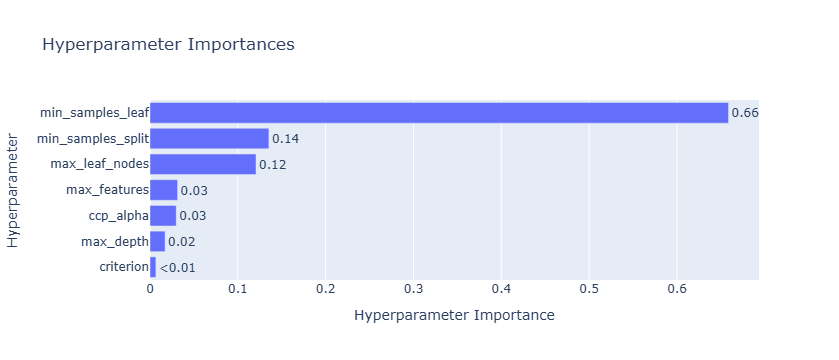

In [16]:
# Plot of which hyperparameters were the most important
plot_param_importances(cstudy).show()

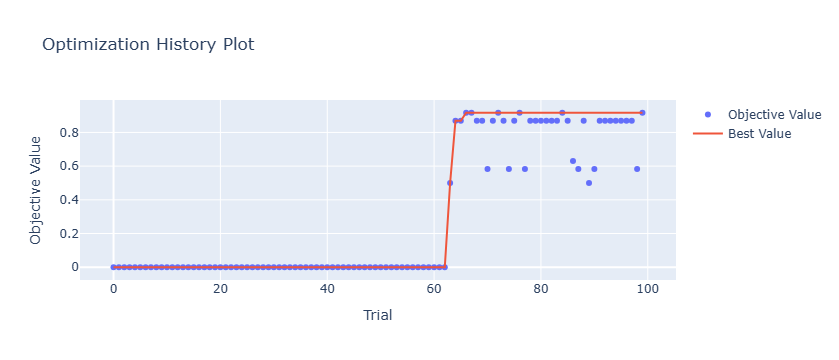

In [17]:
plot_optimization_history(cstudy).show()

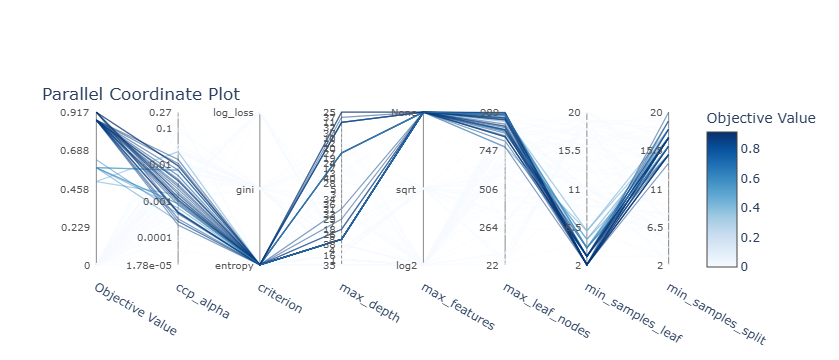

In [18]:
plot_parallel_coordinate(cstudy).show()